# 04 · Perfil de normalidade e limites por atributo (v4)
**CRISP-DM:** Modelagem

**Perfil contextual (proposto):** mediana e escala robusta (1,4826 × MAD) de cada indicador por recurso × tipo de dia (útil/não útil) × hora, em **janelas de 1 h** do histórico. Para um período qualquer:

z = (valor − mediana do contexto) / escala do contexto, contado só no sentido desfavorável (volume nos dois sentidos; 4xx, 5xx e latência só na alta).

**Limite por atributo:** para cada tamanho de faixa L (15, 30 e 60 min), os z do histórico são calculados **fora da amostra** (validação cruzada com 4 blocos contíguos de tempo). O limite do indicador a no recurso r é o **percentil 99** desses z (mínimo 3); um multiplicador c ≥ 1 limitaria os alarmes do histórico a 5% (na prática, c = 1, como na v2).

**Decisão:** o período é **Residual** se algum indicador passa do seu limite; o **indicador responsável** é o que mais passou (em múltiplos do limite).

**Histórico (v4):** o teste é em 01–20/09 e o modelo é ajustado só com dados anteriores, em dois históricos:
- **3 meses** (principal): junho a agosto;
- **1 mês**: agosto.

In [1]:
%run ./00_funcoes.ipynb

00_funcoes (v4) carregado · /home/wsl/gh/mestrado/claude9/v4


In [2]:
import pickle
jan1h = pd.read_parquet(RESULTADOS / "02_janelas_60min.parquet")
periodos = {60: jan1h}
for L in (15, 30):
    periodos[L] = pd.read_parquet(RESULTADOS / f"02_janelas_{L}min.parquet")
for L in periodos:
    periodos[L] = com_semana_anterior(periodos[L], periodos[L])

In [3]:
calib = {}
for mes in MESES_TESTE:
    for hist in HISTORICOS:
        per = periodo_treino(mes, hist)
        for nome, fab in METODOS.items():
            for L in FAIXAS_L:
                calib[(nome, L, mes, hist)] = calibrar(jan1h, periodos[L], fab, per)
        print(f"mês {mes} · histórico {hist} ({per[0]:%d/%m}–{per[1] - pd.Timedelta('1D'):%d/%m}) · c (proposto, 15 min) = "
              f"{calib[(PROPOSTO, 15, mes, hist)]['c']:.2f}")

mês set · histórico 3m (01/06–31/08) · c (proposto, 15 min) = 1.00


mês set · histórico 1m (01/08–31/08) · c (proposto, 15 min) = 1.00


## Limites do método proposto (setembro, histórico de 3 meses)

In [4]:
lim = {L: calib[(PROPOSTO, L, "set", HIST_PRINCIPAL)]["limite"].rename(index=rot).rename(columns=INDICADOR).sort_index()
       for L in FAIXAS_L}
display(pd.concat(lim, axis=1).round(1))

15                                      30                                      60                                 
    volume erros 4xx erros 5xx latência p95 volume erros 4xx erros 5xx latência p95 volume erros 4xx erros 5xx latência p95
A01   10.2      19.1       3.0          5.0    9.5      18.5       3.0          4.7    8.1      14.8       3.0          4.6
A02   10.0      13.2       3.0         20.6    9.4      12.0       3.0         20.8    8.5      13.6       3.0         23.4
A03    4.2       7.0       3.0          7.8    3.8       6.9       3.0          6.9    3.5       6.7       3.0          7.3
A04    4.3       3.3       3.0          9.6    3.9       3.2       3.2          8.4    3.7       3.1       3.0          7.8
A05   71.7      50.0       3.0          6.1   63.6      50.0       3.0          5.9   56.7      50.0       3.0          3.8
A06   29.2     100.0      12.9          8.7   28.6     100.0     100.0          9.0   27.3     100.0     100.0          8.2
A07    9.1      41.8       3.0          9.0    9.0      40.8       3.0          7.6    8.4      40.2       3.0          7.0
A08    7.7      45.0       3.2          4.6    7.5      43.7       3.0          4.2    7.0      42.4       3.0          4.1
A09    8.1      11.4       3.0          8.5    7.2       9.5       3.0          8.2    6.4       7.1       3.0          7.9
A10   12.0      20.9       3.0         10.4    9.8      23.2       3.0          9.4    7.8      20.5       3.0          8.5
A11    8.4      23.0       3.0          6.5    7.9      22.2       3.0          5.7    7.7      20.4       3.0          5.3
A12    4.7       4.0       3.8         10.2    4.5       3.6       3.0          6.6    4.5       3.3       3.0          5.8
A13   31.5       3.8       6.4         15.1   30.6       4.1       5.0         14.2   29.1       4.1       4.5         13.8
A14    5.5      22.0       3.0          7.1    4.7      20.7       3.0          6.7    4.2      18.7       3.0          6.3

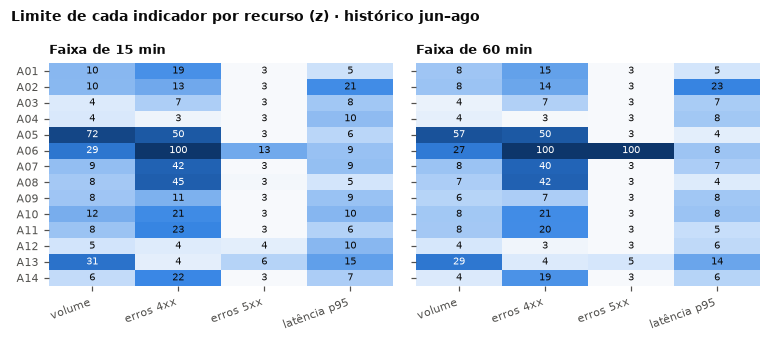

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1), sharey=True)
for ax, L in zip(axes, (15, 60)):
    v = lim[L]
    ax.imshow(np.log10(v.to_numpy()), cmap=CMAP_SEQ, vmin=np.log10(3), vmax=2, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            ax.text(j, i, f"{v.iat[i, j]:.0f}", ha="center", va="center", fontsize=6.3,
                    color="white" if np.log10(v.iat[i, j]) > 1.45 else TXT1)
    ax.set_xticks(range(v.shape[1]))
    ax.set_xticklabels(v.columns, rotation=20, ha="right")
    ax.set_yticks(range(v.shape[0]))
    ax.set_yticklabels(v.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"Faixa de {L} min", loc="left")
fig.suptitle("Limite de cada indicador por recurso (z) · histórico jun–ago", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout()
salvar(fig, "fig_limites")
plt.show()

## Limites com histórico de 3 meses × 1 mês (setembro, 15 min)
Razão entre o limite com 3 meses e com 1 mês. Valores > 1: o histórico longo inclui mais picos (ou mudanças de patamar) e fica mais tolerante.

In [6]:
l3 = calib[(PROPOSTO, 15, "set", "3m")]["limite"]
l1 = calib[(PROPOSTO, 15, "set", "1m")]["limite"]
razao_lim = (l3 / l1).rename(index=rot).rename(columns=INDICADOR).sort_index()
print("razão mediana 3m/1m por indicador:", razao_lim.median().round(2).to_dict())
razao_lim.round(2)

razão mediana 3m/1m por indicador: {'volume': 0.99, 'erros 4xx': 1.32, 'erros 5xx': 1.0, 'latência p95': 0.8}


,volume,erros 4xx,erros 5xx,latência p95
A01,1.03,6.36,1.00,0.53
A02,1.29,1.38,1.00,1.17
A03,0.72,2.33,1.00,0.68
A04,1.04,1.11,1.00,1.00
A05,1.23,1.09,1.00,0.84
A06,0.48,1.00,0.28,0.60
A07,0.95,13.94,1.00,0.78
A08,1.11,0.78,0.87,0.41
A09,0.75,1.43,1.00,0.99
A10,0.90,2.19,1.00,1.10


## Alarmes no histórico (fora da amostra)

In [7]:
alarmes = {k: float((c["razao_cal"] > c["c"]).mean()) for k, c in calib.items()}
alarmes = pd.Series(alarmes).unstack([2, 3])
alarmes.round(4)

set        
                                     3m      1m
Perfil contextual (proposto) 15  0.0334  0.0310
                             30  0.0329  0.0298
                             60  0.0323  0.0294
Semana anterior              15  0.0327  0.0295
                             30  0.0318  0.0278
                             60  0.0318  0.0280
z-score global               15  0.0282  0.0267
                             30  0.0272  0.0250
                             60  0.0265  0.0246

## Residual real no histórico (60 min, proposto, setembro/3 meses): qual indicador?

In [8]:
per = periodo_treino("set", HIST_PRINCIPAL)
cal = calib[(PROPOSTO, 60, "set", HIST_PRINCIPAL)]
p = recortar(periodos[60], per)
tr1h = recortar(jan1h, per)
dobra_p, dobra_1h = dobras(p, per), dobras(tr1h, per)
vezes = pd.DataFrame(index=p.index, columns=ATRIBUTOS, dtype=float)
for k in range(4):
    m = Perfil().ajustar(tr1h[dobra_1h != k])
    vezes.loc[dobra_p == k] = (z_direcional(m.z(p[dobra_p == k])) / cal["limite"].reindex(p.loc[dobra_p == k, "recurso"]).to_numpy()).to_numpy()
res = (vezes > 1).any(axis=1)
ind = vezes[res].astype(float).idxmax(axis=1).map(INDICADOR)
print(f"{int(res.sum())} períodos residuais de 1 h em jun–ago ({res.mean():.1%})")
ind.value_counts()

999 períodos residuais de 1 h em jun–ago (3.2%)


latência p95    300
erros 4xx       290
volume          280
erros 5xx       129
Name: count, dtype: int64

In [9]:
with open(RESULTADOS / "04_calibracao.pkl", "wb") as f:
    pickle.dump(calib, f)
pd.concat(lim, axis=1).to_csv(RESULTADOS / "04_limites.csv")
razao_lim.to_csv(RESULTADOS / "04_razao_limites_3m_1m.csv")
alarmes.to_csv(RESULTADOS / "04_alarmes_historico.csv")
salvar_json({" | ".join(map(str, k)): round(c["c"], 3) for k, c in calib.items()}, "04_multiplicadores.json")
salvar_json(dict(residuais_60=int(res.sum()), frac=float(res.mean()), indicadores=ind.value_counts().to_dict(),
                 razao_lim_mediana=razao_lim.median().to_dict()), "04_resumo.json")